# Business Background
Company: HealthPulse Analytics
Our Role: Data Analyst

HealthPulse Analytics has received patient data from a cardiology research institute.

Management wants us to analyze this data to:
- Understand heart disease patterns.
- Identify important risk factors.
- Develop profiles of potentially high-risk patients.
- Explore predictive analytics for early identification.
- Recommend preventive measures.

# Phase 1 — Dataset Understanding
# Objective:
Understand the dataset's structure, dimensions, columns, data types, and statistical summary before cleaning or analysis.

# Step 1: Import Required Libraries
These libraries cover our EDA, visualization, and statistical analysis requirements.
We'll import machine-learning libraries later when we reach modelling.

In [1]:
# Importing Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import warnings
warnings.filterwarnings("ignore")

# Step 2: Load the Dataset

In [2]:
# Load the heart disease dataset
df = pd.read_csv('heart_disease.csv')
# Display the first 5 rows
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


# Step 3: Check Dataset Dimensions

In [3]:
# Check the number of rows and columns
df.shape

(1025, 14)

# Step 4: Check Column Names

In [6]:
# Display all column names
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='str')

# Step 5: Check Dataset Information
Now let's inspect data types, non-null counts, and memory usage.

In [7]:
# Display dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


# Step 6: Statistical Summary
Let's examine the numerical distribution of every column.

In [8]:
# Generate descriptive statistics for all numerical columns
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


# Initial Statistical Observations

| Variable | Observation |
|---|---|
| Age | Average age: **54.43 years**; range: 29–77 |
| Sex | Mean: 0.696, indicating approximately 69.6% male (code 1) |
| Resting BP | Average: **131.61 mmHg** |
| Cholesterol | Average: **246 mg/dl**; maximum: 564 |
| Fasting Blood Sugar | Approximately 14.9% have FBS >120 |
| Maximum Heart Rate | Average: **149.11 bpm** |
| Exercise-induced Angina | Approximately 33.7% have it |
| Oldpeak | Average: **1.07** |
| Target | Approximately **51.3%** have a positive heart disease label |

# Important Data Observations
Three things deserve attention:
1. Cholesterol maximum = 564: This is unusually high and should be investigated during outlier analysis.
2. ca maximum = 4: Our reference data dictionary specifies a range of 0–3. This needs investigation during data validation.
3. thal minimum = 0: The reference coding starts at 1. We should investigate this as well.
These are potential data-quality issues, not confirmed errors yet.

# Step 7: Check Unique Values

Let's inspect the distinct values in each column, especially categorical and encoded variables.

In [12]:
# Display unique values in every column
for column in df.columns:
    print(f"{column}: {sorted(df[column].unique())}")

age: [np.int64(29), np.int64(34), np.int64(35), np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50), np.int64(51), np.int64(52), np.int64(53), np.int64(54), np.int64(55), np.int64(56), np.int64(57), np.int64(58), np.int64(59), np.int64(60), np.int64(61), np.int64(62), np.int64(63), np.int64(64), np.int64(65), np.int64(66), np.int64(67), np.int64(68), np.int64(69), np.int64(70), np.int64(71), np.int64(74), np.int64(76), np.int64(77)]
sex: [np.int64(0), np.int64(1)]
cp: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
trestbps: [np.int64(94), np.int64(100), np.int64(101), np.int64(102), np.int64(104), np.int64(105), np.int64(106), np.int64(108), np.int64(110), np.int64(112), np.int64(114), np.int64(115), np.int64(117), np.int64(118), np.int64(120), np.int64(122), np.int64(123), np.int64(124), np.int64(125), np.int64(126), np.int64(128), np.int

# Step 8: Check Target Distribution
Let's examine how many patients have heart disease versus those who do not.

In [13]:
# Count patients in each target category
print(df['target'].value_counts())

# Calculate percentage distribution
print("\nTarget Percentage:")
print((df['target'].value_counts(normalize=True) * 100).round(2))

target
1    526
0    499
Name: count, dtype: int64

Target Percentage:
target
1    51.32
0    48.68
Name: proportion, dtype: float64


# Excellent! 👏🏻 This is a very good result.


| Heart Disease (`target`) | Patients | Percentage |
|---|---:|---:|
| Present (1) | 526 | 51.32% |
| Absent (0) | 499 | 48.68% |
| **Total** | **1,025** | **100%** |

# Key Observation
- The dataset is almost balanced between the two target classes.
- There is no significant class imbalance.
- This is favourable for our upcoming logistic regression model.


# What we've established
1. Dataset contains 1,025 patient records and 14 variables.
2. All expected columns are present.
3. No missing values detected through df.info().
4. Data types are predominantly integers, with oldpeak as float.
5. Descriptive statistics have revealed potential unusual values in chol, ca, and thal.
6. Target distribution is reasonably balanced.

# Phase 2 — Data Cleaning & Preprocessing.

# Objective: 
Check data quality, identify inconsistencies, and prepare a reliable dataset for EDA and statistical analysis.

# Step 1: Check Missing Values
Although df.info() showed no missing values, let's verify using Pandas.

In [14]:
# Count missing values in each column
print(df.isnull().sum())

# Calculate total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Total Missing Values: 0


Missing values: 0
All 14 columns are complete.
No imputation required.

# Step 2: Check Duplicate Records
Duplicate rows can affect statistical analysis and model performance.

In [15]:
# Count completely duplicated rows
duplicate_count = df.duplicated().sum()

print("Duplicate Records:", duplicate_count)

Duplicate Records: 723


That's a significant finding.
Step 2 Result: Duplicate Records
- Total records: 1,025
- Duplicate occurrences: 723
- Unique records after removing exact duplicates: 302
Important distinction: df.duplicated().sum() counts repeated occurrences, excluding the first occurrence of each record.

We should investigate this before deleting anything. Removing duplicates will reduce the dataset considerably, so we need to understand the impact.

# Confirm Unique Records

In [16]:
# Calculate dataset size after removing exact duplicates
df_unique = df.drop_duplicates()

print("Original Records:", df.shape[0])
print("Unique Records:", df_unique.shape[0])
print("Duplicate Occurrences:", df.shape[0] - df_unique.shape[0])

Original Records: 1025
Unique Records: 302
Duplicate Occurrences: 723


# This is our first major data-quality finding 🔍

# Duplicate Analysis
| Metric | Records |
|---|---:|
| Original records | 1,025 |
| Unique records | 302 |
| Duplicate occurrences | 723 |
| Duplicate percentage | 70.54% |

# Important Decision
We have no patient ID column to establish whether identical records represent repeated entries for the same patient or different patients with identical measurements.

For this project, we'll:
- Preserve the original dataset as df.
- Create a separate deduplicated dataset as df_clean.
- Document this limitation in our final report.
- Use df_clean for subsequent analysis, while retaining the original for comparison.

# Creating the Deduplicated Dataset

In [17]:
# Remove exact duplicate records without modifying the original dataset
df_clean = df.drop_duplicates().copy()

# Verify the cleaned dataset
print("Records Before Cleaning:", df.shape[0])
print("Records After Cleaning:", df_clean.shape[0])
print("Remaining Duplicates:", df_clean.duplicated().sum())


Records Before Cleaning: 1025
Records After Cleaning: 302
Remaining Duplicates: 0


# Our working dataset df_clean now contains 302 unique records, with zero remaining exact duplicates.

# Step 3: Validate Categorical Values

Earlier, we noticed two potential coding issues:
- ca had a maximum value of 4, while our reference dictionary specifies 0–3.
- thal had a minimum value of 0, while our reference dictionary specifies 1–3.
Let's investigate their frequency before deciding how to handle them

In [18]:
# Check frequency of each ca category
print("CA Value Counts:")
print(df_clean['ca'].value_counts().sort_index())

# Check frequency of each thal category
print("\nTHAL Value Counts:")
print(df_clean['thal'].value_counts().sort_index())

CA Value Counts:
ca
0    175
1     65
2     38
3     20
4      4
Name: count, dtype: int64

THAL Value Counts:
thal
0      2
1     18
2    165
3    117
Name: count, dtype: int64


# Result: Categorical Value Validation
| Column | Unexpected value | Records | Decision |
|---|---:|---:|---|
| `ca` | 4 | 4 | Flag for investigation |
| `thal` | 0 | 2 | Flag for investigation |

Our decision:
- Do not replace ca = 4 with another value.
- Do not replace thal = 0 with another value.
- Preserve these records and document the coding inconsistencies.
We shouldn't invent corrections without knowing the original source coding.

# Step 4: Check Numerical Outliers
Now let's investigate potential extreme values in clinical measurements.

We'll use the IQR (Interquartile Range) method.

Formula:
- IQR = Q3 − Q1
- Lower limit = Q1 − 1.5 × IQR
- Upper limit = Q3 + 1.5 × IQR

In [19]:
# Select continuous numerical columns for outlier detection
numeric_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

# Calculate IQR boundaries and count potential outliers
for col in numeric_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower) | (df_clean[col] > upper)
    ]

    print(f"\n{col}")
    print("Lower Limit:", round(lower, 2))
    print("Upper Limit:", round(upper, 2))
    print("Outlier Count:", len(outliers))


age
Lower Limit: 28.5
Upper Limit: 80.5
Outlier Count: 0

trestbps
Lower Limit: 90.0
Upper Limit: 170.0
Outlier Count: 9

chol
Lower Limit: 115.38
Upper Limit: 370.38
Outlier Count: 5

thalach
Lower Limit: 84.12
Upper Limit: 215.12
Outlier Count: 1

oldpeak
Lower Limit: -2.4
Upper Limit: 4.0
Outlier Count: 5


# Important decision: Should we remove them?
No, not automatically.

These are medical measurements. Extreme values may represent genuine patient conditions rather than data-entry errors. 
Removing them could eliminate clinically important observations.

We'll retain them for now and investigate their actual values.

# Inspect the potential outliers

In [20]:
# Display potential outlier values for each numerical column
for col in numeric_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # Filter records outside IQR boundaries
    outliers = df_clean[
        (df_clean[col] < lower) | (df_clean[col] > upper)
    ]

    print(f"\n--- {col} ---")
    print(outliers[col].sort_values().to_list())


--- age ---
[]

--- trestbps ---
[172, 174, 178, 178, 180, 180, 180, 192, 200]

--- chol ---
[394, 407, 409, 417, 564]

--- thalach ---
[71]

--- oldpeak ---
[4.2, 4.2, 4.4, 5.6, 6.2]


# Outlier Investigation
| Column | Potential outlier values | Assessment |
|---|---|---|
| `age` | None | No outliers |
| `trestbps` | 172–200 | High blood pressure readings; potentially genuine |
| `chol` | 394–564 | High cholesterol readings; potentially genuine |
| `thalach` | 71 | Low maximum heart rate; potentially genuine |
| `oldpeak` | 4.2–6.2 | High ST depression readings; potentially genuine |

# Cleaning decision
Retain all identified outliers. Do not delete or cap them.

# Reason:
- These values are medically meaningful.
- IQR identifies statistical extremes, not necessarily incorrect records.
- Removing genuine extreme readings could distort our heart-disease analysis.

# Documentation
Record this finding for your project:
- IQR method used for numerical outlier detection.
- 20 potential outlier observations identified across five numerical variables.
- No outliers found in age.
- All potential outliers retained because they may represent clinically significant measurements.
    

# Step 5: Data Type Verification

In [21]:
# Check data types after initial cleaning
print(df_clean.dtypes)

age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object


# Phase 3 — Exploratory Data Analysis (EDA)

# Step 1: Univariate Analysis 
— examining individual variables and understanding their distributions.

Step 1: Univariate Analysis
Terminology — Univariate Analysis:
Analysis of one variable at a time to understand its distribution, frequency, central tendency, and spread.

We'll examine:
- Numerical variables: age, trestbps, chol, thalach, oldpeak.
- Categorical variables: sex, cp, fbs, restecg, exang, slope, ca, thal.
- Target variable: heart disease distribution.

# Part 1 — Numerical Variable Summary


In [22]:
# Generate descriptive statistics for numerical variables
numerical_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

print(df_clean[numerical_cols].describe().round(2))

          age  trestbps    chol  thalach  oldpeak
count  302.00    302.00  302.00   302.00   302.00
mean    54.42    131.60  246.50   149.57     1.04
std      9.05     17.56   51.75    22.90     1.16
min     29.00     94.00  126.00    71.00     0.00
25%     48.00    120.00  211.00   133.25     0.00
50%     55.50    130.00  240.50   152.50     0.80
75%     61.00    140.00  274.75   166.00     1.60
max     77.00    200.00  564.00   202.00     6.20


# Important statistical observations
1. Mean vs Median: The mean is higher than the median for trestbps, chol, and oldpeak, suggesting possible right-skewness.
2. Variability: chol has substantial variation (standard deviation 51.75).
3. Range: oldpeak ranges from 0 to 6.2, indicating considerable differences between observations.
These are initial observations; we'll verify distribution shapes visually.

# Part 2 — Distribution Plots
Let's create histograms with KDE curves.

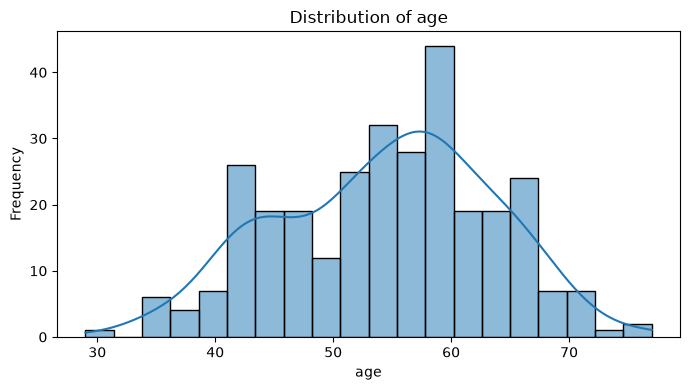

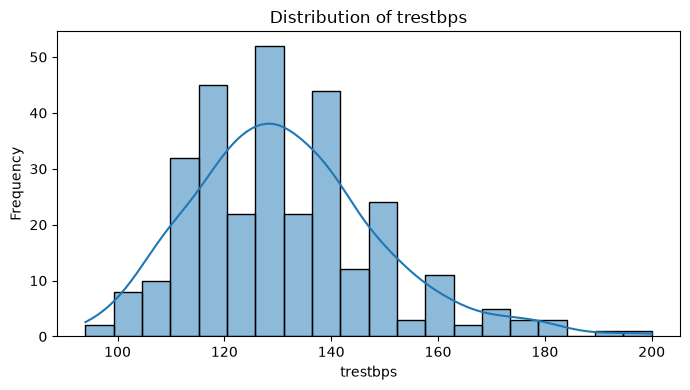

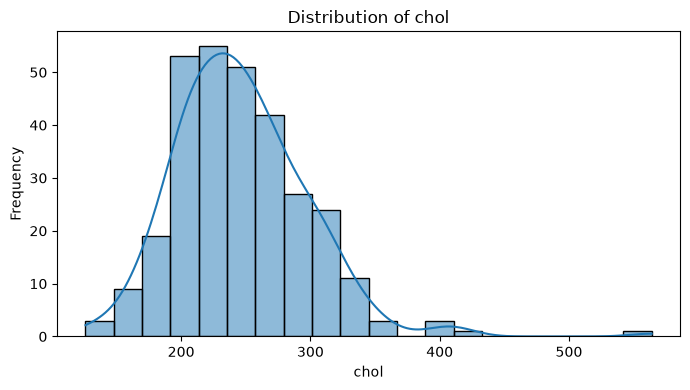

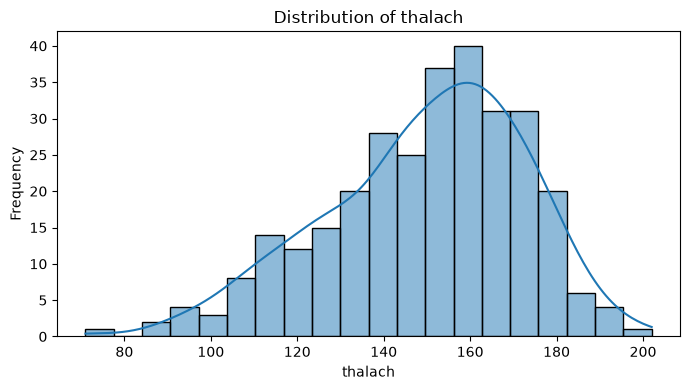

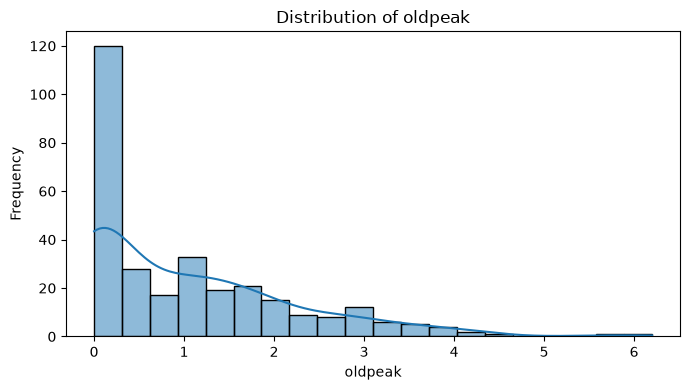

In [23]:
# Plot distributions of numerical variables
numerical_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

for col in numerical_cols:
    plt.figure(figsize=(7, 4))

    # Display histogram and density curve
    sns.histplot(df_clean[col], bins=20, kde=True)

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()

#  Numerical Distribution Interpretation
observations:
| Variable | Distribution | Interpretation |
|---|---|---|
| `age` | Approximately normal | Values are relatively balanced around the centre. |
| `trestbps` | Slightly right-skewed | A few participants have higher blood pressure readings. |
| `chol` | Right-skewed | Some participants have unusually high cholesterol. |
| `thalach` | Left-skewed | Some participants have comparatively low maximum heart rates. |
| `oldpeak` | Highly right-skewed | Most readings are concentrated at lower values, with a few high readings. |

# Key terminology
- Normal distribution: Approximately symmetrical, bell-shaped distribution.
- Right-skewed: Longer tail towards higher values.
- Left-skewed: Longer tail towards lower values.
- KDE: Kernel Density Estimation; a smoothed representation of a variable's distribution.
# Project finding
oldpeak and chol show noticeable right-skewness, while age appears approximately normally distributed.

# Part 3: Categorical Variable Analysis

In [24]:
# Examine frequency distributions of categorical variables
categorical_cols = [
    'sex', 'cp', 'fbs', 'restecg',
    'exang', 'slope', 'ca', 'thal'
]

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df_clean[col].value_counts().sort_index())


--- sex ---
sex
0     96
1    206
Name: count, dtype: int64

--- cp ---
cp
0    143
1     50
2     86
3     23
Name: count, dtype: int64

--- fbs ---
fbs
0    257
1     45
Name: count, dtype: int64

--- restecg ---
restecg
0    147
1    151
2      4
Name: count, dtype: int64

--- exang ---
exang
0    203
1     99
Name: count, dtype: int64

--- slope ---
slope
0     21
1    140
2    141
Name: count, dtype: int64

--- ca ---
ca
0    175
1     65
2     38
3     20
4      4
Name: count, dtype: int64

--- thal ---
thal
0      2
1     18
2    165
3    117
Name: count, dtype: int64


# Important observations
- Sex imbalance: Approximately 68.2% of participants are male.
- Chest pain: Category 0 represents the largest group.
- Fasting blood sugar: Approximately 85.1% have fbs = 0.
- Exercise-induced angina: Approximately 67.2% have exang = 0.
- Resting ECG: Categories 0 and 1 are almost evenly distributed.
- CA and Thal: Unexpected codes identified earlier remain present and should be interpreted cautiously.

# Target Variable Distribution
Let's examine the distribution of our main outcome variable: target.

In [25]:
# Calculate target frequency and percentage
target_counts = df_clean['target'].value_counts().sort_index()

target_percentages = (
    df_clean['target'].value_counts(normalize=True).sort_index() * 100
)

target_summary = pd.DataFrame({
    'Count': target_counts,
    'Percentage': target_percentages.round(2)
})

print(target_summary)

        Count  Percentage
target                   
0         138        45.7
1         164        54.3


# Target Variable Interpretation
| Target | Meaning | Count | Percentage |
|---|---|---:|---:|
| 0 | No heart disease | 138 | 45.7% |
| 1 | Heart disease | 164 | 54.3% |
| **Total** | | **302** | **100%** |

# Key findings
1. 54.3% of participants belong to the heart-disease group.
2. 45.7% belong to the no-heart-disease group.
3. The difference between the two groups is relatively small.
4. The target variable does not show a severe class imbalance.
# Project conclusion so far
Our cleaned dataset contains 302 records, with a reasonably balanced target distribution. This is useful for our upcoming statistical analysis and predictive modelling.

# Step 2 — Bivariate Analysis
We'll investigate relationships between two variables at a time, particularly how demographic and clinical factors relate to heart disease.

# Part 1 — Age vs Heart Disease
# Our objective:
Investigate whether age differs between participants with and without heart disease.

Step 1 — Compare Age Groups

In [26]:
# Compare age statistics across target groups
age_analysis = df_clean.groupby('target')['age'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

# Display results
print(age_analysis.round(2))

        count   mean  median  min  max
target                                
0         138  56.60    58.0   35   77
1         164  52.59    52.0   29   76


# Key Findings
- The average age of the no-heart-disease group is 56.60 years.
- The average age of the heart-disease group is 52.59 years.
- The heart-disease group is approximately 4 years younger on average.
- This is an interesting pattern and challenges the assumption that the heart-disease group must be older.
# Important:
This is an association observed in our dataset, not evidence that younger age causes heart disease or that age is protective.

# Visualization — Box Plot

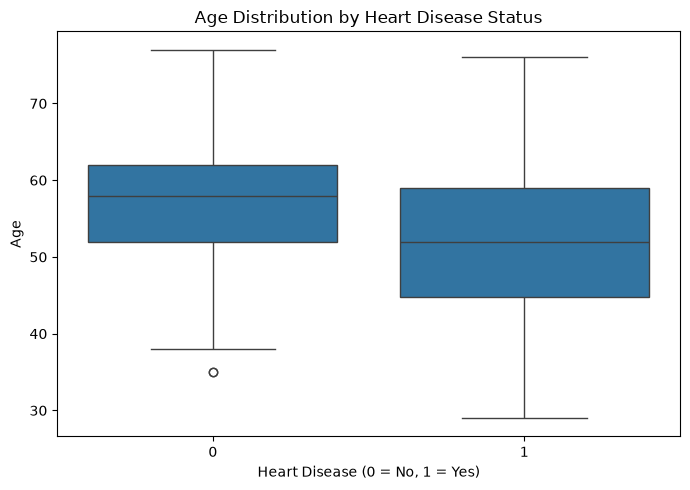

In [27]:
# Compare age distributions across heart disease groups
plt.figure(figsize=(7, 5))

sns.boxplot(data=df_clean, x='target', y='age')

plt.title('Age Distribution by Heart Disease Status')
plt.xlabel('Heart Disease (0 = No, 1 = Yes)')
plt.ylabel('Age')
plt.tight_layout()
plt.show()

# Age vs Heart Disease — Initial Finding
The no-heart-disease group has a higher mean and median age than the heart-disease group. 
We'll retain this as an observation for our final insights.

# Part2 - Sex vs Heart Disease

In [28]:
# Compare heart disease distribution across sex categories
sex_analysis = pd.crosstab(
    df_clean['sex'],
    df_clean['target'],
    margins=True
)

print(sex_analysis)

target    0    1  All
sex                  
0        24   72   96
1       114   92  206
All     138  164  302


In [29]:
# Let's calculate percentages within each sex group.
# Calculate row-wise percentages
sex_percentage = pd.crosstab(
    df_clean['sex'],
    df_clean['target'],
    normalize='index'
) * 100

print(sex_percentage.round(2))

target      0      1
sex                 
0       25.00  75.00
1       55.34  44.66


# Key findings:
- In sex code 0, 75% of records have heart disease.
- In sex code 1, approximately 44.66% have heart disease.
- The observed heart-disease proportion is higher in sex code 0 than in sex code 1.
# Important:
These are associations in this dataset, not proof that sex causes heart disease. We should also verify the dataset's sex coding before assigning labels such as male or female.

# Part 3 — Chest Pain Type (cp) vs Heart Disease
Let's compare heart-disease outcomes across chest-pain categories.

In [30]:
# Compare chest pain type with heart disease
cp_target = pd.crosstab(
    df_clean['cp'],
    df_clean['target']
)

print(cp_target)

target    0   1
cp             
0       104  39
1         9  41
2        18  68
3         7  16


# Calculate row-wise percentages

In [31]:
# Calculate heart disease distribution within each chest pain category
cp_percentage = pd.crosstab(
    df_clean['cp'],
    df_clean['target'],
    normalize='index'
) * 100

print(cp_percentage.round(2))

target      0      1
cp                  
0       72.73  27.27
1       18.00  82.00
2       20.93  79.07
3       30.43  69.57


# Key Findings
1. cp = 0: Only 27.27% have heart disease. Most records (72.73%) belong to the no-disease group.
2. cp = 1: Highest heart-disease proportion at 82%.
3. cp = 2: Nearly 79.07% have heart disease.
4. cp = 3: Approximately 69.57% have heart disease.
# Main insight:
Heart-disease prevalence is substantially higher in categories 1, 2, and 3 than in category 0.

This indicates a strong association between chest-pain category and heart-disease status in our dataset. It does not establish causation. We'll verify the category meanings against the dataset's codebook before assigning clinical labels.

# Part 4 —  (trestbps) vs heart disease.
let's examine resting blood pressure (trestbps) vs heart disease.

In [32]:
# Compare resting blood pressure across target groups
trestbps_summary = df_clean.groupby('target')['trestbps'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

print(trestbps_summary.round(2))

        count    mean  median  min  max
target                                 
0         138  134.40   130.0  100  200
1         164  129.25   130.0   94  180


# Key Findings
1. Mean: The no-disease group has a higher average resting blood pressure (134.40) than the heart-disease group (129.25).
2. Median: Both groups have the same median of 130.
3. Range: The no-disease group has a higher maximum value (200), while the heart-disease group has a lower minimum (94).
# Main insight:
 Resting blood pressure shows only a modest difference between the two groups in this sample. The mean difference alone does not indicate that lower blood pressure protects against heart disease.

# Part 5 —  Cholesterol (chol) vs Heart Disease.

In [33]:
# Compare cholesterol levels across target groups
chol_summary = df_clean.groupby('target')['chol'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

print(chol_summary.round(2))

        count    mean  median  min  max
target                                 
0         138  251.09   249.0  131  409
1         164  242.64   234.5  126  564


# Key Findings
1. Mean: The no-disease group has a slightly higher average cholesterol level (251.09) than the heart-disease group (242.64).
2. Median: The no-disease group also has a higher median (249.0 vs 234.5).
3. Maximum: The heart-disease group has a much higher maximum cholesterol value (564), suggesting an extreme observation.
# Main insight:
Average cholesterol levels are slightly higher in the no-disease group. Therefore, this dataset does not show a simple positive relationship between cholesterol level and heart-disease status.

# Remember: 
cholesterol alone cannot explain heart-disease risk, and extreme observations can influence the mean.

# Part 6 —  Maximum Heart Rate (thalach) vs Heart Disease.

In [34]:
# Compare maximum heart rate across target groups
thalach_summary = df_clean.groupby('target')['thalach'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

print(thalach_summary.round(2))

        count    mean  median  min  max
target                                 
0         138  139.10   142.0   71  195
1         164  158.38   161.0   96  202


# Part 7 —  Exercise-Induced Angina (exang) vs Heart Disease.

In [35]:
# Compare exercise-induced angina with heart disease
exang_table = pd.crosstab(
    df_clean['exang'],
    df_clean['target']
)

print(exang_table)

target   0    1
exang          
0       62  141
1       76   23


# Row-wise percentages


In [36]:
# Calculate heart disease distribution by exercise-induced angina
exang_percentage = pd.crosstab(
    df_clean['exang'],
    df_clean['target'],
    normalize='index'
) * 100

print(exang_percentage.round(2))

target      0      1
exang               
0       30.54  69.46
1       76.77  23.23


# Key findings:
- Without exercise-induced angina, 69.46% of records have heart disease.
- With exercise-induced angina, only 23.23% have heart disease.
- This is an unexpected pattern compared with the usual clinical interpretation, so we should investigate it rather than assume it represents a general medical relationship.

# Part 8 —  Fasting Blood Sugar (fbs) vs Heart Disease

In [37]:
# Compare fasting blood sugar with heart disease
fbs_table = pd.crosstab(
    df_clean['fbs'],
    df_clean['target']
)

print(fbs_table)

target    0    1
fbs             
0       116  141
1        22   23


In [38]:
# — Calculate percentages
# Calculate heart disease distribution by fasting blood sugar
fbs_percentage = pd.crosstab(
    df_clean['fbs'],
    df_clean['target'],
    normalize='index'
) * 100

print(fbs_percentage.round(2))

target      0      1
fbs                 
0       45.14  54.86
1       48.89  51.11


# Key findings:
- For fbs = 0, 54.86% have heart disease.
- For fbs = 1, 51.11% have heart disease.
- The difference is small (3.75 percentage points).
Main insight: Fasting blood sugar does not show a strong difference in heart-disease prevalence between the two groups in this dataset.

# Part 9 — Resting ECG (restecg) vs Heart Disease

In [39]:
# Compare resting ECG categories with heart disease
restecg_table = pd.crosstab(
    df_clean['restecg'],
    df_clean['target']
)

print(restecg_table)

target    0   1
restecg        
0        79  68
1        56  95
2         3   1


In [40]:
# Calculate row-wise percentages
# Calculate heart disease distribution by resting ECG category
restecg_percentage = pd.crosstab(
    df_clean['restecg'],
    df_clean['target'],
    normalize='index'
) * 100

print(restecg_percentage.round(2))

target       0      1
restecg              
0        53.74  46.26
1        37.09  62.91
2        75.00  25.00


# Part 10 — Oldpeak vs Heart Disease
Terminology — Oldpeak: ST depression induced by exercise relative to rest. It is a numerical clinical measurement.

Let's compare its distribution between the two target groups.


In [41]:
# Compare oldpeak statistics across heart disease groups
oldpeak_summary = df_clean.groupby('target')['oldpeak'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

print(oldpeak_summary.round(2))

        count  mean  median  min  max
target                               
0         138  1.59     1.4  0.0  6.2
1         164  0.59     0.2  0.0  4.2


# Interpretation:
- The no-disease group has a higher average Oldpeak (1.59) than the disease group (0.59).
- The median also follows the same pattern: 1.40 vs 0.20.
- Both groups contain zero values.
- The maximum Oldpeak is higher in the no-disease group (6.20).
# Key insight: 
In this dataset, Oldpeak is unexpectedly higher in the group without heart disease. This is worth investigating during statistical analysis. We should not assume that higher Oldpeak means lower heart-disease risk.

# Part 11 — Slope vs Heart Disease
Terminology — Slope: Describes the slope of the peak exercise ST segment. It is a categorical clinical variable.

First, generate the frequency table:

In [42]:
# Compare heart disease counts across slope categories
slope_counts = pd.crosstab(
    df_clean['slope'],
    df_clean['target']
)

print(slope_counts)

target   0    1
slope          
0       12    9
1       91   49
2       35  106


In [43]:
# Calculate heart disease distribution within each slope category
slope_percentage = pd.crosstab(
    df_clean['slope'],
    df_clean['target'],
    normalize='index'
) * 100

print(slope_percentage.round(2))

target      0      1
slope               
0       57.14  42.86
1       65.00  35.00
2       24.82  75.18


# Interpretation:
- Slope 0: 42.86% have heart disease.
- Slope 1: 35% have heart disease, the lowest proportion among the three categories.
- Slope 2: 75.18% have heart disease, the highest proportion.
# Key insight:
 Slope category 2 has a notably higher proportion of heart-disease cases in this dataset. This suggests an association between slope category and heart disease.

# Part 12 — Number of Major Vessels (ca) vs Heart Disease
Terminology — ca: Number of major blood vessels (0–3 in the supplied project dictionary) visualized by fluoroscopy.
Your dataset also contains category 4, which we flagged earlier as a coding difference.
First, generate the count table:

In [44]:
# Compare heart disease counts across ca categories
ca_counts = pd.crosstab(
    df_clean['ca'],
    df_clean['target']
)

print(ca_counts)

target   0    1
ca             
0       45  130
1       44   21
2       31    7
3       17    3
4        1    3


In [45]:
# Calculate heart disease distribution within each ca category
ca_percentage = pd.crosstab(
    df_clean['ca'],
    df_clean['target'],
    normalize='index'
) * 100

print(ca_percentage.round(2))

target      0      1
ca                  
0       25.71  74.29
1       67.69  32.31
2       81.58  18.42
3       85.00  15.00
4       25.00  75.00


# Interpretation:
- Category 0: 74.29% have heart disease.
- Categories 1, 2 and 3: The proportion of heart disease decreases across these categories.
- Category 4: 75% have heart disease, but this category contains only 4 observations (3 with disease, 1 without). It is too small for a reliable conclusion.
# Important observation:
The pattern is unexpected. In conventional clinical interpretation, a higher number of major vessels showing abnormalities is generally associated with greater risk. Our dataset shows the opposite for categories 0–3.

# Part 13 — Thal (thal) vs Heart Disease
Terminology — thal: A categorical result associated with a thallium stress test, used to assess blood flow to the heart muscle.
The dataset contains categories 0, 1, 2 and 3. Category 0 was already flagged as a coding difference.

In [46]:
# Compare heart disease counts across thal categories
thal_counts = pd.crosstab(
    df_clean['thal'],
    df_clean['target']
)

print(thal_counts)

target   0    1
thal           
0        1    1
1       12    6
2       36  129
3       89   28


In [47]:
# Calculate heart disease distribution within each thal category
thal_percentage = pd.crosstab(
    df_clean['thal'],
    df_clean['target'],
    normalize='index'
) * 100

print(thal_percentage.round(2))

target      0      1
thal                
0       50.00  50.00
1       66.67  33.33
2       21.82  78.18
3       76.07  23.93


# Interpretation:
- Thal 0: 50% in each group, but only 2 observations. Too small to interpret.
- Thal 1: 66.67% have no heart disease.
- Thal 2: 78.18% have heart disease — the highest proportion among categories with substantial observations.
- Thal 3: 76.07% have no heart disease.
# Key insight: 
Thal category 2 shows a substantially higher proportion of heart-disease cases, while category 3 shows the opposite pattern.

# Step 3 — Multivariate Analysis

# Part 1 — Correlation Analysis
1. Terminology: Correlation
Correlation measures the strength and direction of the relationship between two numerical variables.

Correlation coefficient ranges from -1 to +1:

| Value | Meaning |
|---|---|
| +1 | Perfect positive correlation |
| 0 | No linear correlation |
| -1 | Perfect negative correlation |

Examples:
- Positive: As X increases, Y tends to increase.
- Negative: As X increases, Y tends to decrease.
- Near zero: Little or no linear relationship.

2. Calculate the Correlation Matrix
We'll use Pearson correlation to examine relationships among numerical variables, including the target.

In [49]:
# Calculate the Pearson correlation matrix
correlation_matrix = df_clean.corr(method='pearson')

# Display correlation values
print(correlation_matrix.round(2))

           age   sex    cp  trestbps  chol   fbs  restecg  thalach  exang  \
age       1.00 -0.09 -0.06      0.28  0.21  0.12    -0.11    -0.40   0.09   
sex      -0.09  1.00 -0.05     -0.06 -0.20  0.05    -0.06    -0.05   0.14   
cp       -0.06 -0.05  1.00      0.05 -0.07  0.10     0.04     0.29  -0.39   
trestbps  0.28 -0.06  0.05      1.00  0.13  0.18    -0.12    -0.05   0.07   
chol      0.21 -0.20 -0.07      0.13  1.00  0.01    -0.15    -0.01   0.06   
fbs       0.12  0.05  0.10      0.18  0.01  1.00    -0.08    -0.01   0.02   
restecg  -0.11 -0.06  0.04     -0.12 -0.15 -0.08     1.00     0.04  -0.07   
thalach  -0.40 -0.05  0.29     -0.05 -0.01 -0.01     0.04     1.00  -0.38   
exang     0.09  0.14 -0.39      0.07  0.06  0.02    -0.07    -0.38   1.00   
oldpeak   0.21  0.10 -0.15      0.19  0.05  0.00    -0.06    -0.34   0.29   
slope    -0.16 -0.03  0.12     -0.12  0.00 -0.06     0.09     0.38  -0.26   
ca        0.30  0.11 -0.20      0.10  0.09  0.14    -0.08    -0.23   0.13   

# Creating  a heatmap

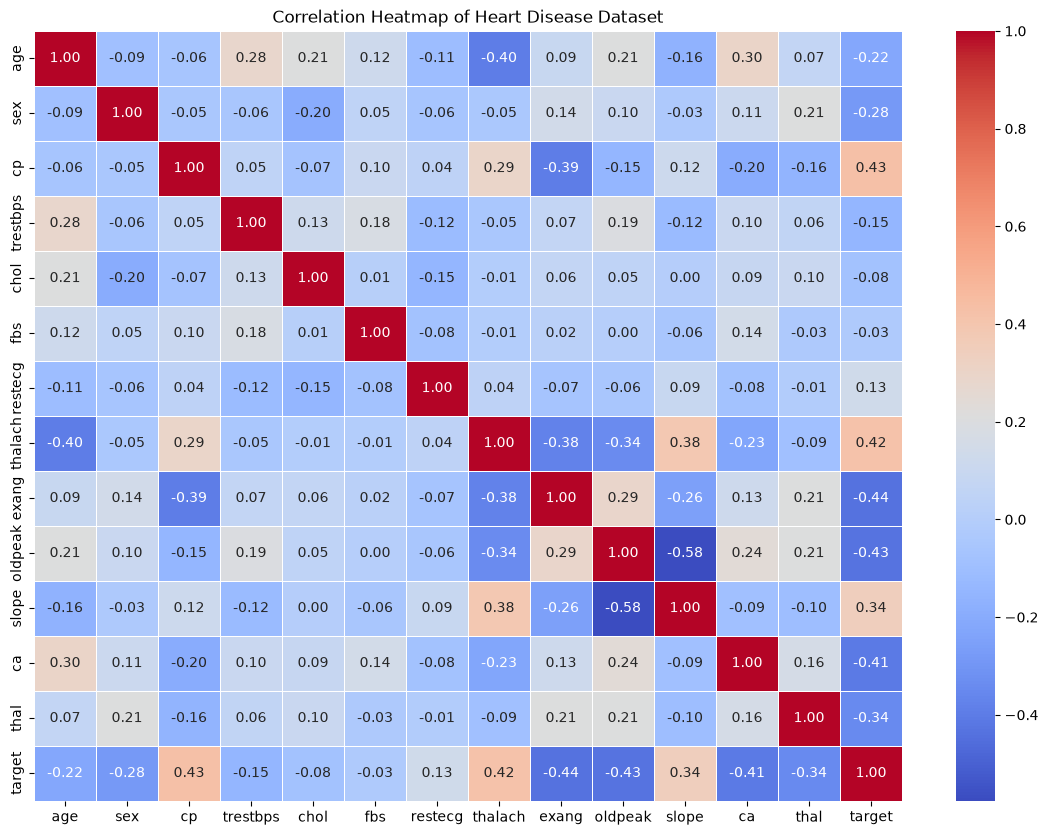

In [50]:
# Set the figure size
plt.figure(figsize=(14, 10))

# Create correlation heatmap
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

# Add title
plt.title('Correlation Heatmap of Heart Disease Dataset')

# Display the plot
plt.show()

# Part2 - Pairplot Analysis

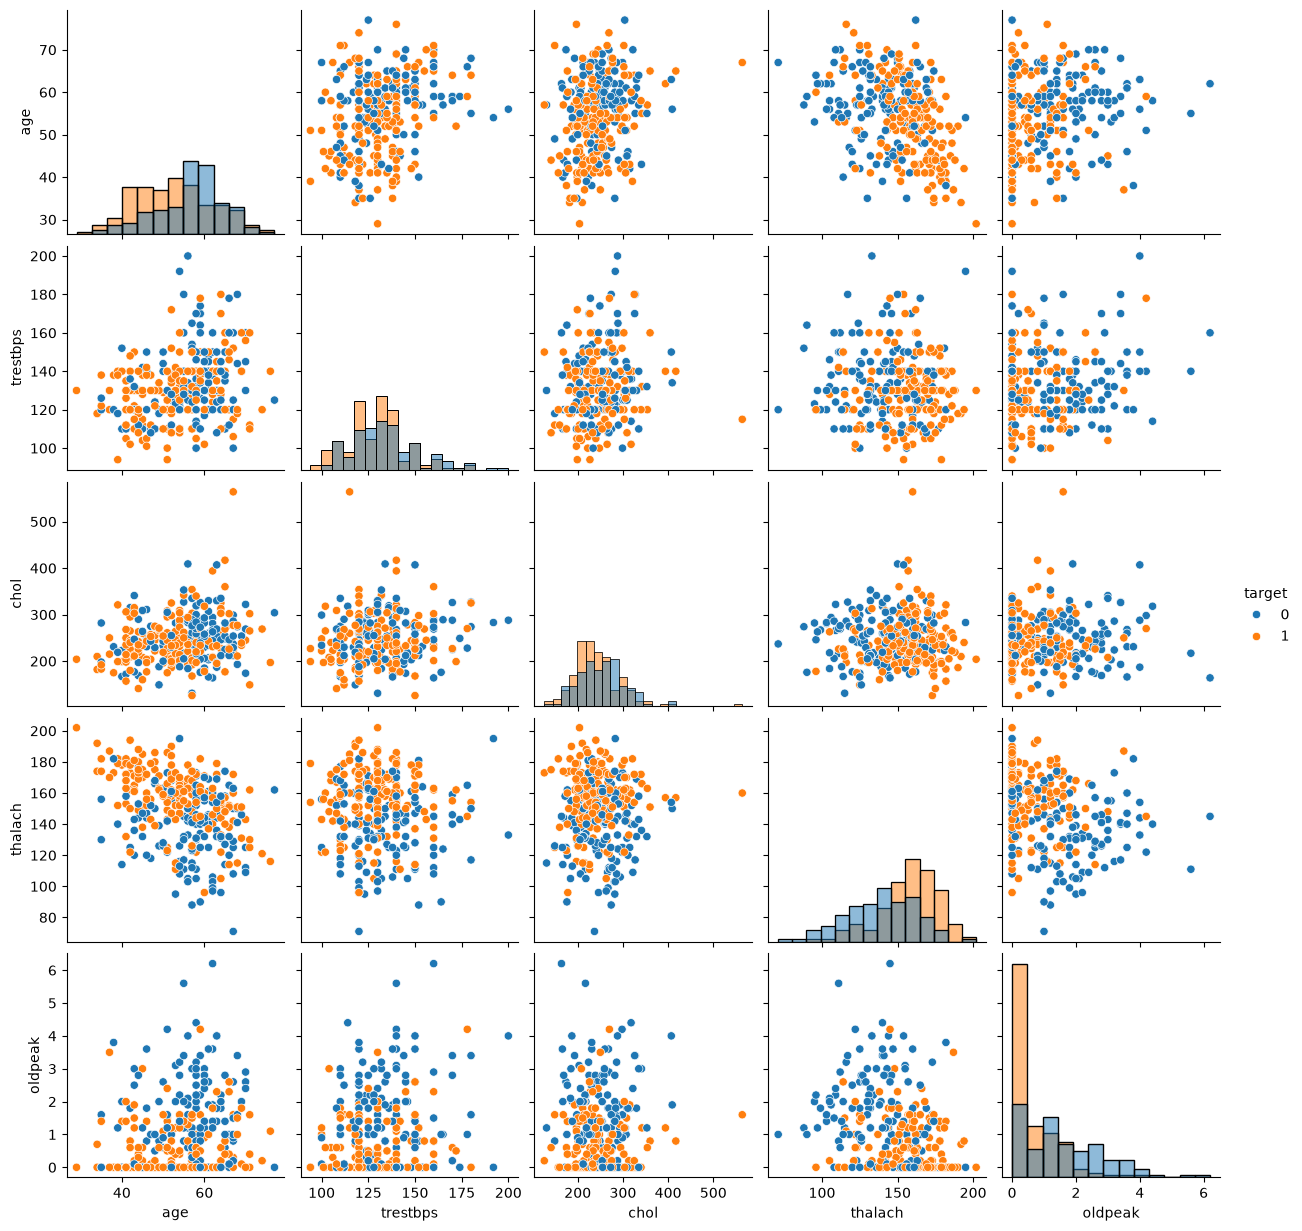

In [51]:
# Select numerical variables for pairplot analysis
pairplot_data = df_clean[
    ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'target']
]

# Generate pairplot and distinguish target classes
sns.pairplot(
    pairplot_data,
    hue='target',
    diag_kind='hist'
)

# Display the plot
plt.show()

# Part3- Combined Risk-Factor Analysis

We'll investigate Chest Pain (cp) + Exercise-Induced Angina (exang) vs Target.

In [52]:
# Compare heart disease counts across chest pain and exercise angina combinations
combined_counts = pd.crosstab(
    [df_clean['cp'], df_clean['exang']],
    df_clean['target']
)

print(combined_counts)

target     0   1
cp exang        
0  0      34  29
   1      70  10
1  0       8  38
   1       1   3
2  0      14  61
   1       4   7
3  0       6  13
   1       1   3


In [53]:
# Calculate disease percentage for each combination
# Calculate row-wise percentages for each combination
combined_percentage = pd.crosstab(
    [df_clean['cp'], df_clean['exang']],
    df_clean['target'],
    normalize='index'
) * 100

print(combined_percentage.round(2))

target        0      1
cp exang              
0  0      53.97  46.03
   1      87.50  12.50
1  0      17.39  82.61
   1      25.00  75.00
2  0      18.67  81.33
   1      36.36  63.64
3  0      31.58  68.42
   1      25.00  75.00


# Phase 4 — Statistical Analysis

# Part 1 — Pearson Correlation Significance Test.
# Objective
We already calculated correlation coefficients. Now we'll calculate their p-values to assess statistical significance.

In [54]:
# Test correlation significance between numerical variables and target

numerical_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

for col in numerical_cols:
    corr, p_value = stats.pearsonr(df_clean[col], df_clean['target'])

    print(f"{col}:")
    print(f"Correlation: {corr:.3f}")
    print(f"P-Value: {p_value:.5f}")
    print("-" * 30)

age:
Correlation: -0.221
P-Value: 0.00010
------------------------------
trestbps:
Correlation: -0.146
P-Value: 0.01093
------------------------------
chol:
Correlation: -0.081
P-Value: 0.15804
------------------------------
thalach:
Correlation: 0.420
P-Value: 0.00000
------------------------------
oldpeak:
Correlation: -0.429
P-Value: 0.00000
------------------------------


# Part 2 — Chi-Square Test of Independence
Objective: Test whether categorical variables have statistically significant associations with heart disease (target).

We'll test these variables:

sex, cp, fbs, restecg, exang, slope, ca, thal

In [56]:
# Chi-Square Test for categorical variables

categorical_cols = [
    'sex', 'cp', 'fbs', 'restecg',
    'exang', 'slope', 'ca', 'thal'
]

for col in categorical_cols:

    # Create contingency table
    table = pd.crosstab(df_clean[col], df_clean['target'])

    # Perform Chi-Square test
    chi2, p_value, dof, expected = stats.chi2_contingency(table)

    print(f"\nVariable: {col}")
    print(f"Chi-Square Statistic: {chi2:.3f}")
    print(f"P-Value: {p_value:.5f}")
    print(f"Degrees of Freedom: {dof}")
    print("Significant" if p_value < 0.05 else "Not Significant")


Variable: sex
Chi-Square Statistic: 23.084
P-Value: 0.00000
Degrees of Freedom: 1
Significant

Variable: cp
Chi-Square Statistic: 80.979
P-Value: 0.00000
Degrees of Freedom: 3
Significant

Variable: fbs
Chi-Square Statistic: 0.092
P-Value: 0.76114
Degrees of Freedom: 1
Not Significant

Variable: restecg
Chi-Square Statistic: 9.730
P-Value: 0.00771
Degrees of Freedom: 2
Significant

Variable: exang
Chi-Square Statistic: 55.456
P-Value: 0.00000
Degrees of Freedom: 1
Significant

Variable: slope
Chi-Square Statistic: 46.889
P-Value: 0.00000
Degrees of Freedom: 2
Significant

Variable: ca
Chi-Square Statistic: 73.690
P-Value: 0.00000
Degrees of Freedom: 4
Significant

Variable: thal
Chi-Square Statistic: 84.610
P-Value: 0.00000
Degrees of Freedom: 3
Significant


# Overall Statistical Insights
- Chest pain, thal, major vessels and exercise-induced angina show statistically significant associations with the target.
- Maximum heart rate and oldpeak show moderate correlations with the target.
- Cholesterol and fasting blood sugar did not show statistically significant relationships in the tests performed.
- Some observed relationships are counterintuitive and require careful interpretation.
- Small category counts and unusual dataset encodings are important limitations.
# Project Documentation
Statistical Analysis Summary: Statistical testing identified significant associations between heart disease status and several demographic and clinical variables. Pearson correlation and Chi-Square tests highlighted important patterns, while cholesterol and fasting blood sugar showed no statistically significant associations in their respective tests.

# Phase 5 — Risk Factor Identification

# Part 1: Identify Important Variables
We'll use the results from our completed EDA and statistical tests.
# A. Important categorical variables

| Variable | Finding |
|---|---|
| `cp` — Chest Pain | Strong statistical association |
| `thal` | Strong statistical association |
| `ca` — Major Vessels | Strong statistical association |
| `exang` — Exercise Angina | Strong statistical association |
| `slope` | Significant association |
| `sex` | Significant association |
| `restecg` | Significant association |

# B. Important numerical variables

| Variable | Correlation with Target | Finding |
|---|---:|---|
| `oldpeak` | -0.429 | Moderate association |
| `thalach` | +0.420 | Moderate association |
| `age` | -0.221 | Weak association |
| `trestbps` | -0.146 | Weak association |
| `chol` | -0.081 | Not statistically significant |

# C. Variables requiring further investigation

- fbs: No significant association detected.
- chol: No significant linear correlation detected.
- ca and thal: Unusual category values require codebook verification.
- oldpeak, exang and some other variables show patterns that deserve careful interpretation.
Important: These are dataset associations, not confirmed clinical risk factors. We must not interpret negative correlations as protective effects.

# Part 2: High-Risk vs Low-Risk Pattern Comparison

We'll compare the two groups:
- Target 0: No heart disease.
- Target 1: Heart disease.
Based on our earlier results:

| Variable | Target 0 Mean | Target 1 Mean | Observation |
|---|---:|---:|---|
| Age | 56.60 | 52.59 | Higher in Target 0 |
| Resting BP | 134.40 | 129.25 | Higher in Target 0 |
| Cholesterol | 251.09 | 242.64 | Higher in Target 0 |
| Maximum Heart Rate | 139.10 | 158.38 | Higher in Target 1 |
| Oldpeak | 1.59 | 0.59 | Higher in Target 0 |

# Key Observations
1. The disease group has a higher average maximum heart rate.
2. The no-disease group has higher average age, resting BP and cholesterol.
3. Oldpeak is unexpectedly higher in the no-disease group.
4. These patterns demonstrate why we should investigate actual dataset results rather than assume conventional medical relationships.
# Conclusion:
The variables show different patterns across the two groups. None should independently be treated as a reliable diagnostic indicator.

# Part 3: Strongest Indicator Summary

# A. Strongest categorical associations
Based on Chi-Square statistics:

| Variable | Chi-Square | Finding |
|---|---:|---|
| Thal | 84.610 | Strong statistical evidence |
| Chest Pain (`cp`) | 80.979 | Strong statistical evidence |
| Major Vessels (`ca`) | 73.690 | Strong statistical evidence |
| Exercise Angina (`exang`) | 55.456 | Strong statistical evidence |
| Slope | 46.889 | Significant |
| Sex | 23.084 | Significant |
| Resting ECG | 9.730 | Significant |

These statistics indicate evidence of association, not necessarily the strength of each association. 
A formal effect-size measure such as Cramér's V would be needed for that comparison.

# B. Strongest numerical associations

| Variable | Correlation | Finding |
|---|---:|---|
| Oldpeak | -0.429 | Moderate |
| Thalach | +0.420 | Moderate |
| Age | -0.221 | Weak |
| Trestbps | -0.146 | Weak |
| Cholesterol | -0.081 | Very weak |

# C. Final Risk-Factor Identification
Our analysis highlights these variables for further investigation:
- Chest pain (cp)
- Thal
- Major vessels (ca)
- Exercise-induced angina (exang)
- Slope
- Oldpeak
- Maximum heart rate (thalach)
Project conclusion: These variables show notable statistical relationships with heart disease status in this dataset. However, unusual coding, duplicate removal, small category counts and unexpected associations must be considered before drawing clinical conclusions.

# Phase 6 — Predictive Modelling

# Objective: 
Build a Machine Learning model that predicts whether a person has heart disease (target = 1) or does not (target = 0).
We'll use Logistic Regression, a supervised machine-learning algorithm for binary classification.

# Part 1 — Feature Selection & Preparation

Step 1: Separate Features and Target
- Features (X): The 13 input variables used for prediction.
- Target (y): The variable we want to predict.
One important preparation: several columns (cp, restecg, slope, ca, thal) represent categories, not continuous numerical measurements. We'll use one-hot encoding rather than treating their numeric labels as ordered values.

In [57]:
# Identify categorical variables for one-hot encoding
categorical_cols = ['cp', 'restecg', 'slope', 'ca', 'thal']

# Separate input features and target
X = df_clean.drop(columns=['target'])
y = df_clean['target']


# Convert categorical variables into dummy variables
X = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

# Check the prepared dataset
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())
print("\nPrepared features:")
print(X.head())

Features shape: (302, 22)
Target shape: (302,)

Target distribution:
target
1    164
0    138
Name: count, dtype: int64

Prepared features:
   age  sex  trestbps  chol  fbs  thalach  exang  oldpeak  cp_1  cp_2  ...  \
0   52    1       125   212    0      168      0      1.0     0     0  ...   
1   53    1       140   203    1      155      1      3.1     0     0  ...   
2   70    1       145   174    0      125      1      2.6     0     0  ...   
3   61    1       148   203    0      161      0      0.0     0     0  ...   
4   62    0       138   294    1      106      0      1.9     0     0  ...   

   restecg_2  slope_1  slope_2  ca_1  ca_2  ca_3  ca_4  thal_1  thal_2  thal_3  
0          0        0        1     0     1     0     0       0       0       1  
1          0        0        0     0     0     0     0       0       0       1  
2          0        0        0     0     0     0     0       0       0       1  
3          0        0        1     1     0     0     0       0     

# Part 2 — Train-Test Split

Concept
We'll divide our dataset into two sets:
- Training data (80%): Used to train the model.
- Testing data (20%): Used to evaluate predictions on unseen observations.
We'll use stratify=y to preserve the target distribution in both sets.

In [58]:
from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Check dataset dimensions
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Features: (241, 22)
Testing Features: (61, 22)

Training Target Distribution:
target
1    131
0    110
Name: count, dtype: int64

Testing Target Distribution:
target
1    33
0    28
Name: count, dtype: int64


# Part 3 — Model Training

Now we'll train our Logistic Regression model.

Step 1: Feature Scaling
Logistic Regression generally benefits from scaling numerical features because they have different measurement ranges.

We'll use StandardScaler inside a pipeline. This ensures the scaler learns from training data only, preventing data leakage.

In [59]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create Logistic Regression pipeline
logistic_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])

# Train the model using training data
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


# Part 4 — Model Evaluation

Now we'll evaluate how well the model predicts heart disease using our 61 unseen test records.

We'll calculate four important metrics:
1. Accuracy: Overall percentage of correct predictions.
2. Precision: Of predicted disease cases, how many were actually disease cases?
3. Recall: Of actual disease cases, how many did the model identify?
4. F1-Score: Balance between precision and recall.

In [60]:
# Generating Predictions
# Predict target values using test data
y_pred = logistic_model.predict(X_test)

# Display actual and predicted values
results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

print(results.head(15))

    Actual  Predicted
0        0          0
1        0          1
2        0          0
3        0          1
4        0          1
5        0          0
6        1          1
7        0          0
8        1          1
9        0          0
10       1          1
11       1          1
12       0          1
13       1          1
14       1          0


# Evaluation Metrics

These metrics tell us how well the Logistic Regression model predicts heart disease.

In [61]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate model evaluation metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:", round(recall_score(y_test, y_pred), 3))
print("F1-Score:", round(f1_score(y_test, y_pred), 3))

Accuracy: 0.836
Precision: 0.848
Recall: 0.848
F1-Score: 0.848


# Interpretation of Evaluation Metrics

| Metric | Score | Interpretation |
|---|---:|---|
| Accuracy | 83.6% | Correctly predicted 83.6% of all test records. |
| Precision | 84.8% | Of all records predicted as heart disease, 84.8% were actually positive. |
| Recall | 84.8% | Detected 84.8% of all actual heart disease cases. |
| F1-Score | 84.8% | Balanced performance between precision and recall. |

# Important observation:
Recall is particularly important in this project because we want to understand 
how many actual positive cases the model successfully identifies.

# Part 5 — Confusion Matrix

Terminology:
- True Negative (TN): Correctly predicted no disease.
- False Positive (FP): Predicted disease, but actual result was no disease.
- False Negative (FN): Actual disease, but model predicted no disease.
- True Positive (TP): Correctly predicted disease.

In [62]:
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[23  5]
 [ 5 28]]


# Confusion Matrix Interpretation
| Outcome | Value | Meaning |
|---|---:|---|
| True Negative (TN) | 23 | Correctly identified 23 cases without heart disease. |
| False Positive (FP) | 5 | Incorrectly predicted disease in 5 cases. |
| False Negative (FN) | 5 | Missed 5 actual heart disease cases. |
| True Positive (TP) | 28 | Correctly identified 28 cases with heart disease. |

# Key observations:
- Total test records: 61.
- Correct predictions: 23 + 28 = 51.
- Incorrect predictions: 5 + 5 = 10.
- The model correctly identified 28 out of 33 actual positive cases.
- It missed 5 positive cases.

# Phase 7 — Business Insights & Recommendations

# Part 1: Key Findings from the Analysis
Based on our actual EDA, statistical tests and model results, here are the major findings.

| No. | Finding | Evidence |
|---|---|---|
| 1 | Age showed a negative association with the target. | Correlation: -0.221 |
| 2 | Chest pain type (`cp`) had a significant association with the target. | Chi-square p-value < 0.001 |
| 3 | Maximum heart rate (`thalach`) showed a positive association. | Correlation: +0.420 |
| 4 | Exercise-induced angina (`exang`) had a significant association. | Chi-square p-value < 0.001 |
| 5 | ST depression (`oldpeak`) showed a negative association. | Correlation: -0.429 |
| 6 | Cholesterol did not show a statistically significant association in our test. | p-value: 0.158 |
| 7 | Fasting blood sugar (`fbs`) did not show a significant association. | Chi-square p-value: 0.761 |
| 8 | Logistic Regression achieved promising classification results. | Accuracy: 83.6%; F1-score: 84.8% |

# Important interpretation
These are associations observed in this dataset, not proof of medical causation or individual disease risk.

# Part 2: Business Recommendations
Based on our analysis, here are the practical recommendations.

| No. | Recommendation | Purpose |
|---|---|---|
| 1 | Monitor important clinical indicators such as chest pain type, maximum heart rate and ST depression. | Support further clinical assessment. |
| 2 | Pay attention to exercise-related symptoms and patterns. | Encourage appropriate medical evaluation. |
| 3 | Use data-driven analysis to identify patterns across different patient groups. | Support better healthcare research. |
| 4 | Improve data quality and standardize category codes. | Reduce inconsistencies in future analysis. |
| 5 | Collect larger and more representative datasets. | Improve analytical reliability. |
| 6 | Validate predictive models on independent datasets before considering real-world use. | Reduce the risk of misleading predictions. |

# Part 3: Business Perspective
The analysis demonstrates how data analytics and machine learning can help healthcare organizations:
- Explore patterns in patient data.
- Identify variables associated with heart disease.
- Support data-informed research.
- Develop predictive models for further validation.
- Improve data-driven decision-making.
Important: The model should not be used independently for diagnosis or treatment decisions.

# Part 4: Final Project Conclusion
Here is the overall conclusion based on our completed analysis.

The project, "Pulse of Prevention: Analyzing Heart Health for Better Outcomes," explored heart disease-related patterns using Python, statistical analysis and machine learning.

The analysis identified several variables associated with the target, including chest pain type, maximum heart rate, exercise-induced angina, ST depression and other clinical indicators.

Statistical hypothesis testing helped distinguish significant associations from those that were not statistically significant.

A Logistic Regression classification model was developed and evaluated on a held-out test dataset.

# Part 5: Final Model Performance:
| Metric | Result |
|---|---:|
| Accuracy | 83.6% |
| Precision | 84.8% |
| Recall | 84.8% |
| F1-Score | 84.8% |

# Part 6: Project Limitations
These are the limitations we must document:
1. Dataset size: After removing 723 duplicate occurrences, 302 unique records remained.
2. Duplicate uncertainty: Without patient IDs, we cannot establish whether repeated records represent duplicate patients.
3. Category coding: Some ca and thal values fall outside the supplied PDF's category definitions.
4. Limited features: The dataset does not include every factor that may influence heart disease.
5. Model validation: Evaluation used one 80:20 train-test split, with only 61 test records.
6. Model limitations: Logistic Regression may not capture complex nonlinear relationships.
7. Clinical limitation: Predictions are educational and analytical outputs, not medical diagnoses.